In [3]:
from Model import RandomForest
import matplotlib.pyplot as plt
import math
# dữ liệu đã chuẩn bị
from prepare_data import X_train, y_train, X_val, y_val

# ======================================================
# Metric
# ======================================================
def accuracy(y_true, y_pred):
    correct = 0
    for yt, yp in zip(y_true, y_pred):
        if yt == yp:
            correct += 1
    return correct / len(y_true)


def evaluate(model, X, y):
    preds = [model.predict(x) for x in X]
    return accuracy(y, preds)


# ======================================================
# Plot helper
# ======================================================
def plot_curve(x, y, xlabel, title):
    plt.figure(figsize=(13, 4))
    plt.plot(x, y, marker="o")
    plt.xlabel(xlabel)
    plt.ylabel("Validation Accuracy")
    plt.title(title)
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ======================================================
# BASE hyperparameters (cố định)
# ======================================================
def get_base_params(X_train):
    return dict(
        max_depth=20,
        min_samples=2,
        max_leaf_nodes=50,
        max_features=int(math.sqrt(len(X_train[0]))),
        max_thresholds=10,
        random_state=42
    )


# ======================================================
# 1. Validation curve: n_estimators (FAST – warm start)
# ======================================================
def validation_curve_n_estimators(
    X_train, y_train, X_val, y_val, n_estimators_range
):
    base = get_base_params(X_train)

    rf = RandomForest(
        n_trees=max(n_estimators_range),
        **base
    )

    scores = []
    prev = 0

    for n in n_estimators_range:
        print(f"[n_estimators] training up to {n}")
        rf.fit(X_train, y_train, n_new_trees=n - prev)
        scores.append(evaluate(rf, X_val, y_val))
        prev = n

    return scores


# ======================================================
# 2. Validation curve: max_depth
# ======================================================
def validation_curve_max_depth(
    X_train, y_train, X_val, y_val, max_depth_range, n_trees
):
    base = get_base_params(X_train)
    scores = []

    for d in max_depth_range:
        print(f"[max_depth] depth={d}")
        rf = RandomForest(
            n_trees=n_trees,
            max_depth=d,
            min_samples=base["min_samples"],
            max_leaf_nodes=base["max_leaf_nodes"],
            max_features=base["max_features"],
            max_thresholds=base["max_thresholds"],
            random_state=base["random_state"]
        )
        rf.fit(X_train, y_train)
        scores.append(evaluate(rf, X_val, y_val))

    return scores


# ======================================================
# 3. Validation curve: max_leaf_nodes
# ======================================================
def validation_curve_max_leaf_nodes(
    X_train, y_train, X_val, y_val, max_leaf_nodes_range, n_trees, max_depth
):
    base = get_base_params(X_train)
    scores = []

    for m in max_leaf_nodes_range:
        print(f"[max_leaf_nodes] nodes={m}")
        rf = RandomForest(
            n_trees=n_trees,
            max_depth=max_depth,
            min_samples=base["min_samples"],
            max_leaf_nodes=m,
            max_features=base["max_features"],
            max_thresholds=base["max_thresholds"],
            random_state=base["random_state"]
        )
        rf.fit(X_train, y_train)
        scores.append(evaluate(rf, X_val, y_val))

    return scores


[n_estimators] training up to 5
[n_estimators] training up to 10
[n_estimators] training up to 15
[n_estimators] training up to 20
[n_estimators] training up to 25
[n_estimators] training up to 30
[n_estimators] training up to 35
[n_estimators] training up to 40
[n_estimators] training up to 45
[n_estimators] training up to 50
[n_estimators] training up to 55
[n_estimators] training up to 60
[n_estimators] training up to 65
[n_estimators] training up to 70
[n_estimators] training up to 75
[n_estimators] training up to 80
[n_estimators] training up to 85
[n_estimators] training up to 90
[n_estimators] training up to 95
[n_estimators] training up to 100
[n_estimators] training up to 105
[n_estimators] training up to 110
[n_estimators] training up to 115


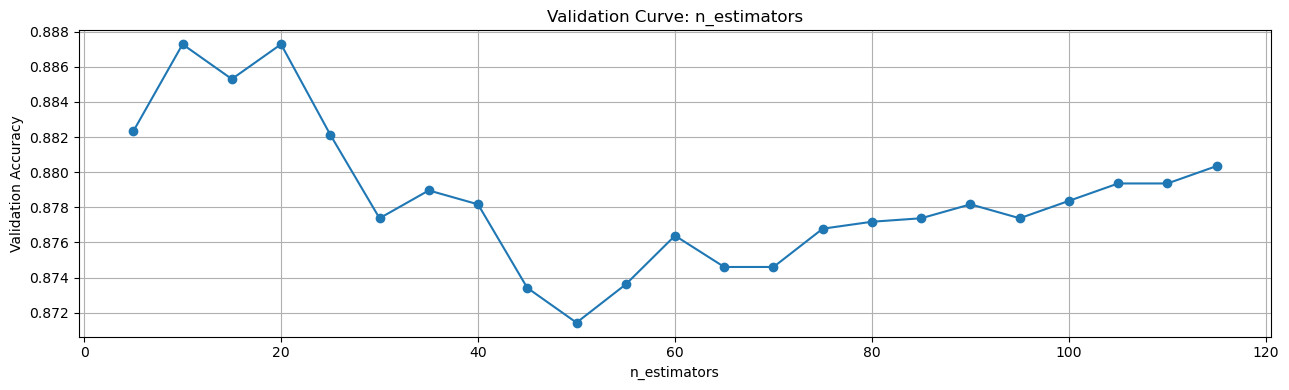

In [13]:


# ---------- n_estimators ----------
n_estimators_range = range(5, 120, 5)

scores_n = validation_curve_n_estimators(
    X_train, y_train, X_val, y_val, n_estimators_range
)

plot_curve(
    n_estimators_range,
    scores_n,
    "n_estimators",
    "Validation Curve: n_estimators"
)


[max_depth] depth=2
[max_depth] depth=3
[max_depth] depth=4
[max_depth] depth=5
[max_depth] depth=6
[max_depth] depth=7
[max_depth] depth=8
[max_depth] depth=9
[max_depth] depth=10
[max_depth] depth=11
[max_depth] depth=12
[max_depth] depth=13
[max_depth] depth=14
[max_depth] depth=15


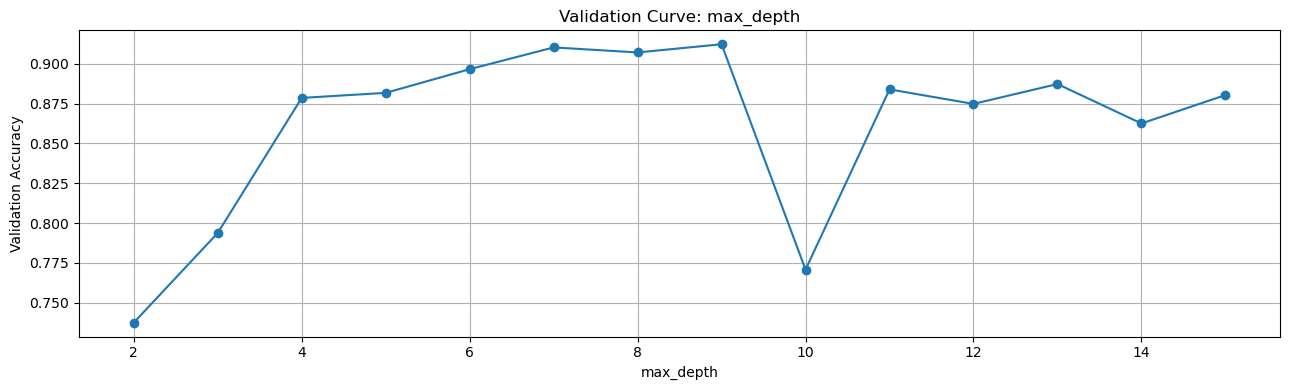

In [12]:
# ---------- max_depth ----------
max_depth_range = range(2,16,1)

scores_d = validation_curve_max_depth(
    X_train, y_train, X_val, y_val,
    max_depth_range,
    n_trees=10
)

plot_curve(
    max_depth_range,
    scores_d,
    "max_depth",
    "Validation Curve: max_depth"
)

[max_leaf_nodes] nodes=10
[max_leaf_nodes] nodes=12
[max_leaf_nodes] nodes=14
[max_leaf_nodes] nodes=16
[max_leaf_nodes] nodes=18
[max_leaf_nodes] nodes=20
[max_leaf_nodes] nodes=22
[max_leaf_nodes] nodes=24
[max_leaf_nodes] nodes=26
[max_leaf_nodes] nodes=28
[max_leaf_nodes] nodes=30
[max_leaf_nodes] nodes=32
[max_leaf_nodes] nodes=34
[max_leaf_nodes] nodes=36
[max_leaf_nodes] nodes=38


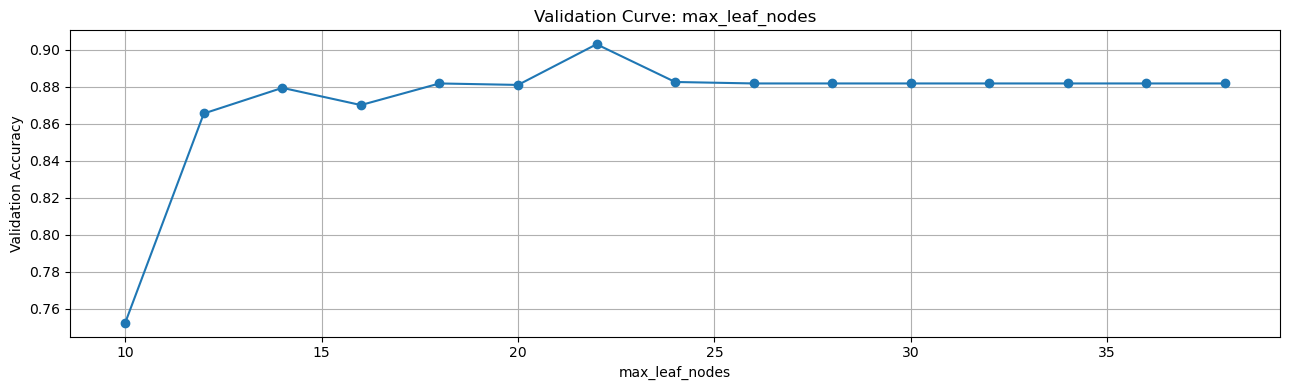

In [8]:
# ---------- max_leaf_nodes ----------
max_leaf_nodes_range = range(10, 40, 2)

scores_l = validation_curve_max_leaf_nodes(
    X_train, y_train, X_val, y_val,
    max_leaf_nodes_range,
    n_trees=10,
    max_depth=5
)

plot_curve(
    max_leaf_nodes_range,
    scores_l,
    "max_leaf_nodes",
    "Validation Curve: max_leaf_nodes"
)